In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

print("Data Cleaning & Reporting Automation")
print("Libraries imported successfully!")


Data Cleaning & Reporting Automation
Libraries imported successfully!


In [3]:

# Create a sample business dataset
data = {
    "Customer": ["Anu", "Rahul", "Meera", "Anu", "Kiran",
                 "Rahul ", "Diya", "Arun", "Meera", "Sara"],
    "Department": ["Sales", "Marketing", "Sales", "Sales",
                   "Finance", "Marketing", "IT", "IT",
                   "Sales", "Finance"],
    "Sales": [1200, 2500, np.nan, 1200, 1800,
              2500, np.nan, 3200, 2100, 1600],
    "Region": ["South", "North", "South", "South",
               "East", "North", "West", "West",
               "South", "East"],
    "Date": ["2026-01-05", "2026-01-12", "2026-01-15",
             "2026-01-05", "2026-02-01", "2026-02-05",
             "2026-02-10", "2026-02-15", "2026-03-01",
             "2026-03-05"]
}

df = pd.DataFrame(data)

print("Original Dataset:")
display(df)

print("Dataset shape:", df.shape)
print("Missing values per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())


Original Dataset:


,Customer,Department,Sales,Region,Date
0,Anu,Sales,1200.0,South,2026-01-05
1,Rahul,Marketing,2500.0,North,2026-01-12
2,Meera,Sales,NaN,South,2026-01-15
3,Anu,Sales,1200.0,South,2026-01-05
4,Kiran,Finance,1800.0,East,2026-02-01
5,Rahul,Marketing,2500.0,North,2026-02-05
6,Diya,IT,NaN,West,2026-02-10
7,Arun,IT,3200.0,West,2026-02-15
8,Meera,Sales,2100.0,South,2026-03-01
9,Sara,Finance,1600.0,East,2026-03-05


Dataset shape: (10, 5)
Missing values per column:
Customer      0
Department    0
Sales         2
Region        0
Date          0
dtype: int64
Duplicate rows: 1


In [4]:

# Keep a copy of the original dataset for comparison
original_df = df.copy()

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Clean extra spaces in text columns
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

# 3. Fill missing sales with the median
df["Sales"] = df["Sales"].fillna(df["Sales"].median())

# 4. Convert Date to a proper date format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Automated cleaning completed!")
print("Original rows:", len(original_df))
print("Rows after removing duplicates:", len(df))
print("\nMissing values after cleaning:")
print(df.isnull().sum())

display(df)


Automated cleaning completed!
Original rows: 10
Rows after removing duplicates: 9

Missing values after cleaning:
Customer      0
Department    0
Sales         0
Region        0
Date          0
dtype: int64


,Customer,Department,Sales,Region,Date
0,Anu,Sales,1200.0,South,2026-01-05
1,Rahul,Marketing,2500.0,North,2026-01-12
2,Meera,Sales,2100.0,South,2026-01-15
4,Kiran,Finance,1800.0,East,2026-02-01
5,Rahul,Marketing,2500.0,North,2026-02-05
6,Diya,IT,2100.0,West,2026-02-10
7,Arun,IT,3200.0,West,2026-02-15
8,Meera,Sales,2100.0,South,2026-03-01
9,Sara,Finance,1600.0,East,2026-03-05


In [5]:

# Automated Data Cleaning Report

report = pd.DataFrame({
    "Metric": [
        "Original number of rows",
        "Rows after cleaning",
        "Duplicate rows removed",
        "Missing values before cleaning",
        "Missing values after cleaning"
    ],
    "Value": [
        len(original_df),
        len(df),
        int(original_df.duplicated().sum()),
        int(original_df.isnull().sum().sum()),
        int(df.isnull().sum().sum())
    ]
})

print("AUTOMATED DATA CLEANING REPORT")
print("=" * 35)
display(report)


AUTOMATED DATA CLEANING REPORT


,Metric,Value
0,Original number of rows,10
1,Rows after cleaning,9
2,Duplicate rows removed,1
3,Missing values before cleaning,2
4,Missing values after cleaning,0


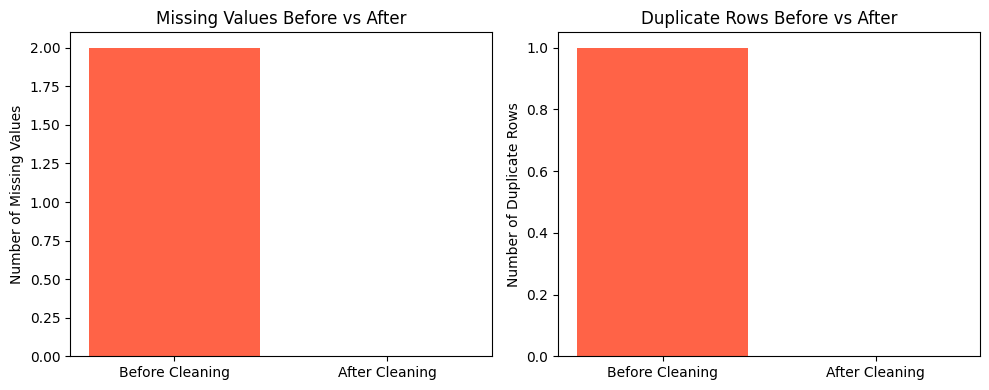

In [6]:

# Compare missing values and duplicate rows before and after cleaning

missing_before = original_df.isnull().sum().sum()
missing_after = df.isnull().sum().sum()

duplicates_before = int(original_df.duplicated().sum())
duplicates_after = int(df.duplicated().sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(
    ["Before Cleaning", "After Cleaning"],
    [missing_before, missing_after],
    color=["tomato", "seagreen"]
)
axes[0].set_title("Missing Values Before vs After")
axes[0].set_ylabel("Number of Missing Values")

axes[1].bar(
    ["Before Cleaning", "After Cleaning"],
    [duplicates_before, duplicates_after],
    color=["tomato", "seagreen"]
)
axes[1].set_title("Duplicate Rows Before vs After")
axes[1].set_ylabel("Number of Duplicate Rows")

plt.tight_layout()
plt.show()


Total Sales by Department:


,Department,Sales
0,Finance,3400.0
1,IT,5300.0
2,Marketing,5000.0
3,Sales,5400.0


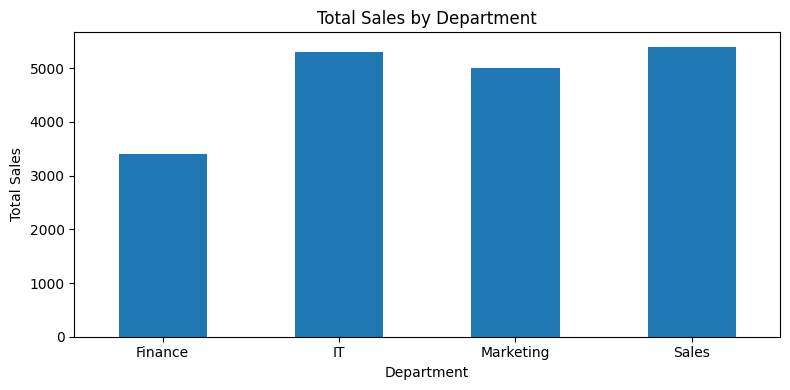

In [7]:

# Calculate total sales by department
sales_summary = df.groupby("Department")["Sales"].sum()

print("Total Sales by Department:")
display(sales_summary.reset_index())

# Create a bar chart
sales_summary.plot(kind="bar", figsize=(8, 4))

plt.title("Total Sales by Department")
plt.xlabel("Department")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [8]:

# Save the cleaned dataset and report as CSV files

df.to_csv("cleaned_business_data.csv", index=False)
report.to_csv("data_cleaning_report.csv", index=False)

print("Files saved successfully!")
print("1. cleaned_business_data.csv")
print("2. data_cleaning_report.csv")


Files saved successfully!
1. cleaned_business_data.csv
2. data_cleaning_report.csv


In [12]:

from google.colab import files

files.download("cleaned_business_data.csv")
files.download("data_cleaning_report.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:

print("CONCLUSION")
print("-" * 40)
print("The Data Cleaning and Reporting Automation project")
print("uses Python and Pandas to clean a sample business dataset.")
print("It handles missing values, removes duplicate rows,")
print("standardizes text, and converts dates into date format.")
print("It also generates a cleaning report and visual summaries.")
print("The cleaned dataset and report can be saved as CSV files.")
print("This project demonstrates how data cleaning and reporting")
print("tasks can be automated to reduce manual effort.")


CONCLUSION
----------------------------------------
The Data Cleaning and Reporting Automation project
uses Python and Pandas to clean a sample business dataset.
It handles missing values, removes duplicate rows,
standardizes text, and converts dates into date format.
It also generates a cleaning report and visual summaries.
The cleaned dataset and report can be saved as CSV files.
This project demonstrates how data cleaning and reporting
tasks can be automated to reduce manual effort.


In [13]:

print("FINAL PROJECT VERIFICATION")
print("-" * 35)
print("Original rows:", len(original_df))
print("Cleaned rows:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())
print("Missing values remaining:", df.isnull().sum().sum())
print("Cleaning report created:", "report" in globals())


FINAL PROJECT VERIFICATION
-----------------------------------
Original rows: 10
Cleaned rows: 9
Duplicate rows remaining: 0
Missing values remaining: 0
Cleaning report created: True
